In [1]:
# Cell 1: Clean Imports
import matplotlib.pyplot as plt
from pathlib import Path
# Custom package modules
from behavior_fw.utils.psth import extract_experiment_psth
from behavior_fw.analysis.calc_velocities import get_velocities
from behavior_fw.visualization.plot_density import (
    plot_dynamic_cartesian_densities,
    plot_dynamic_polar_densities,
)
from behavior_fw.visualization.plot_psth import (
    plot_condition_psth_summary,
    plot_single_experiment_psth,
)
from behavior_fw.visualization.plot_trajectory import plot_single_fly_trajectory

In [2]:
from behavior_fw.io.load_dataset import load_experiment_dataset

path_dir_data = Path("/home/athira/CF/PhD/Data")
# path_dir_dataset  = path_dir_data / "FW_Darkness_Bonsai_08082026" 
path_dir_dataset  = path_dir_data / "LocalSearch_OptoCL" 


In [3]:

# from pathlib import Path
# import pandas as pd

# # Find all cached tracking files
# cache_files = list(path_dir_dataset.rglob("*ProcessedTracking.csv"))

# for filepath in cache_files:
#     df = pd.read_csv(filepath)
#     if "Vr_smooth" in df.columns and "Vr_abs" not in df.columns:
#         df["Vr_abs"] = df["Vr_smooth"].abs()
#         df.to_csv(filepath, index=False)

# print(
#     f"Successfully updated {len(cache_files)} cached files with 'Vr_abs'!"
# )

In [12]:
from behavior_fw.core.dataset import create_experiments_metadata, select_exp_condition

df_metadata = create_experiments_metadata(path_dir_dataset)
path_to_metadata = path_dir_dataset / "metadata.csv"
df_metadata.to_csv(path_to_metadata)
df_metadata

,folder_name,folder_path,date,time,datetime,genotype,protocol,medium
0,20260814_165206_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,165206,2026-08-14 16:52:06,Gr43a,OptoCL,ATR
1,20260814_171722_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,171722,2026-08-14 17:17:22,Gr43a,OptoCLReplay,ATR
2,20260815_095930_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,095930,2026-08-15 09:59:30,Gr43a,OptoCL,ATR
3,20260815_102821_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,102821,2026-08-15 10:28:21,Gr43a,OptoCLReplay,ATR
4,20260815_110148_Gr43a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,110148,2026-08-15 11:01:48,Gr43a,OptoCL,NR
...,...,...,...,...,...,...,...,...
116,20260927_214323_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,214323,2026-09-27 21:43:23,Gr5a,OptoCL,ATR
117,20260927_220910_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,220910,2026-09-27 22:09:10,Gr5a,OptoCL,NR
118,20260927_223457_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,223457,2026-09-27 22:34:57,Gr5a,OptoCL,NR
119,20260927_225846_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,225846,2026-09-27 22:58:46,Gr5a,OptoCL,NR


In [5]:
df_Gr43a_ATR_CL = select_exp_condition(df_metadata, genotype="Gr5a", protocol="OptoCL", medium="ATR")
df_Gr43a_ATR_CL

,folder_name,folder_path,date,time,datetime,genotype,protocol,medium
63,20260816_105347_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260816,105347,2026-08-16 10:53:47,Gr5a,OptoCL,ATR
64,20260816_125518_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260816,125518,2026-08-16 12:55:18,Gr5a,OptoCL,ATR
65,20260809_175603_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260809,175603,2026-08-09 17:56:03,Gr5a,OptoCL,ATR
66,20260809_182046_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260809,182046,2026-08-09 18:20:46,Gr5a,OptoCL,ATR
67,20260809_184634_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260809,184634,2026-08-09 18:46:34,Gr5a,OptoCL,ATR
69,20260809_193955_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260809,193955,2026-08-09 19:39:55,Gr5a,OptoCL,ATR
71,20260809_203206_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260809,203206,2026-08-09 20:32:06,Gr5a,OptoCL,ATR
73,20260924_164719_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260924,164719,2026-09-24 16:47:19,Gr5a,OptoCL,ATR
74,20260924_173331_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260924,173331,2026-09-24 17:33:31,Gr5a,OptoCL,ATR
75,20260925_090010_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260925,090010,2026-09-25 09:00:10,Gr5a,OptoCL,ATR


In [6]:
# 1. Standard fast run (Loads from cache if available, calculates if missing)
dataset = load_experiment_dataset(df_Gr43a_ATR_CL, fps=60.0)

# 2. (Optional) Force re-computing velocities for all flies from raw tracking:
# dataset = load_experiment_dataset(df_Gr43a_ATR_CL, fps=60.0, force_recompute=True)

Error processing index 2 (20260809_175603): 'ori_angle_cal'
Error processing index 3 (20260809_182046): 'ori_angle_cal'
Error processing index 4 (20260809_184634): 'ori_angle_cal'
Error processing index 5 (20260809_193955): 'ori_angle_cal'
Error processing index 6 (20260809_203206): 'ori_angle_cal'


In [7]:
# Loads processed CSVs if they exist, or calculates LOWESS once and caches to disk
dataset = load_experiment_dataset(df_Gr43a_ATR_CL, fps=60.0)

print(f"Loaded {len(dataset)} flies into memory!")
print("Columns in df_track:", dataset[0]["df_track"].columns.tolist())

Error processing index 2 (20260809_175603): 'ori_angle_cal'
Error processing index 3 (20260809_182046): 'ori_angle_cal'
Error processing index 4 (20260809_184634): 'ori_angle_cal'
Error processing index 5 (20260809_193955): 'ori_angle_cal'
Error processing index 6 (20260809_203206): 'ori_angle_cal'
Loaded 41 flies into memory!
Columns in df_track: ['Index', 'X_cal', 'Y_cal', 'ori_angle_cal', 'X_px', 'Y_px', 'ori_angle', 'LowResTimestampTick', 'LowResFrameNumber', 'HighResFrameNumber', 'X', 'Y', 'LEDstate', 'Vf_smooth', 'Vs_smooth', 'Vr_smooth', 'Vt_smooth', 'Vr_abs']


3.0149359929088706 -5.121893862193295 0.38520028219800495


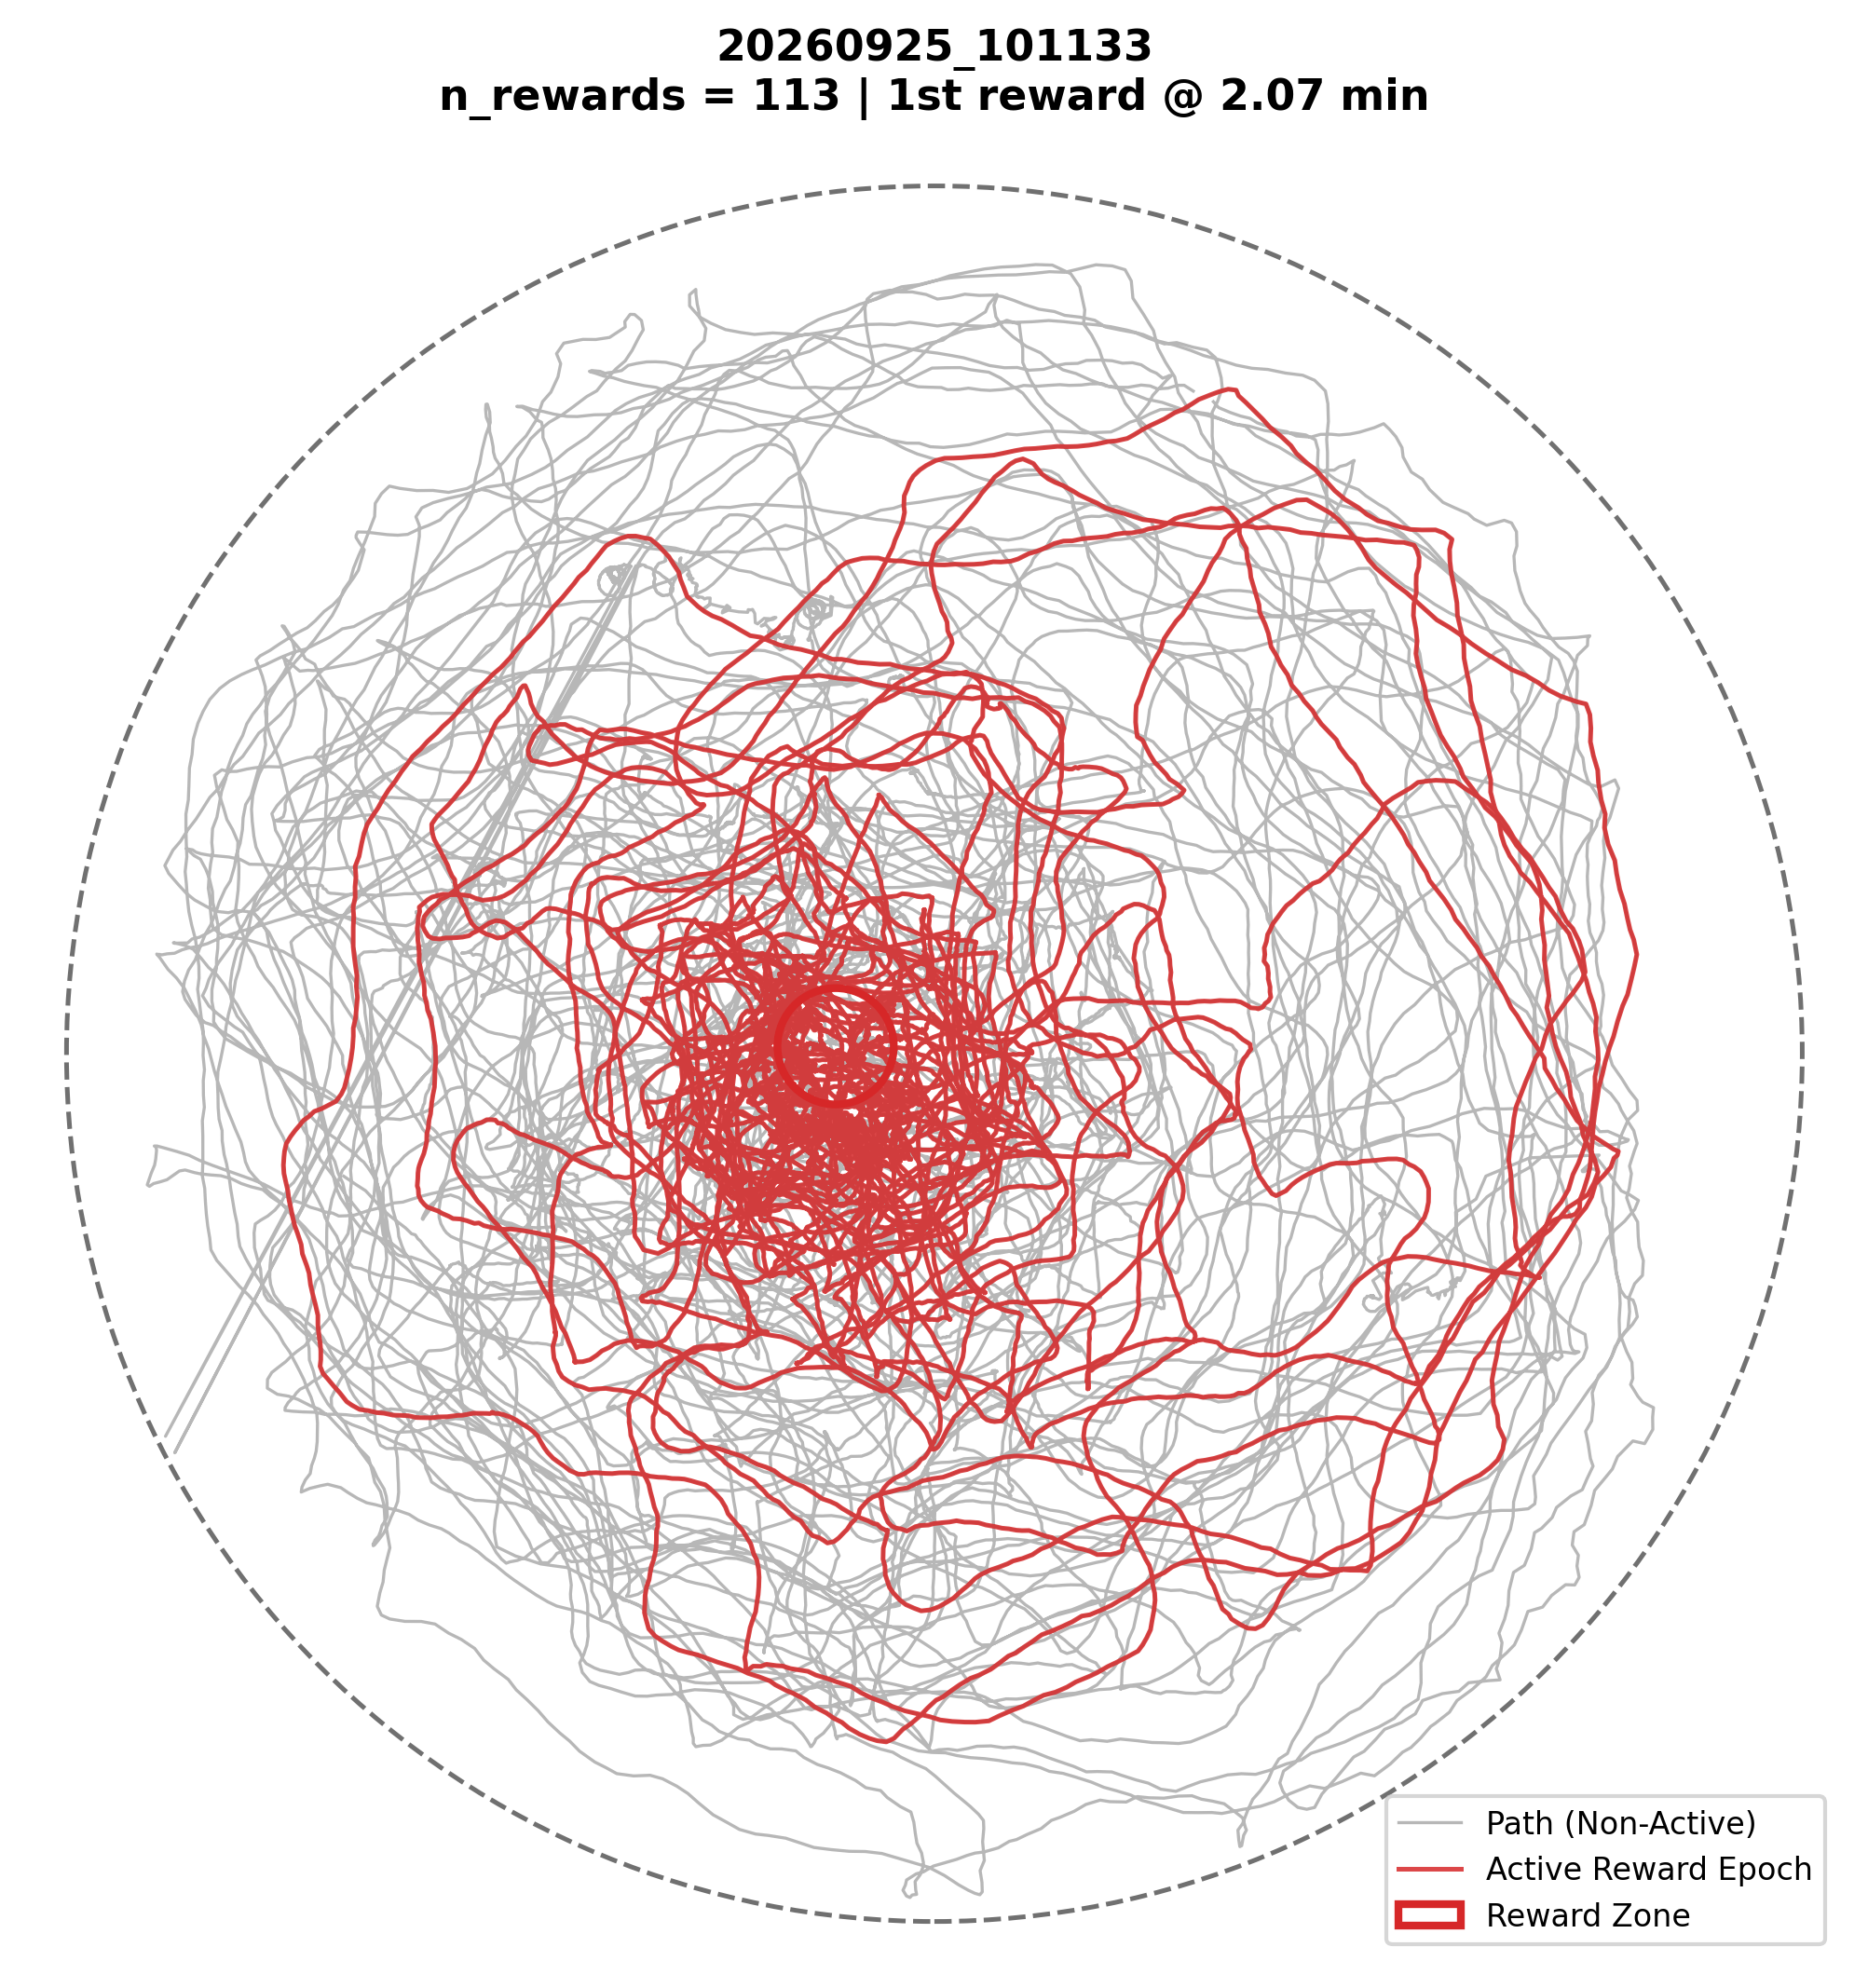

In [8]:
exp = dataset[5]  # Pick first fly

fig, ax = plot_single_fly_trajectory(exp, arena_r=45.0, fps=60.0)
plt.show()

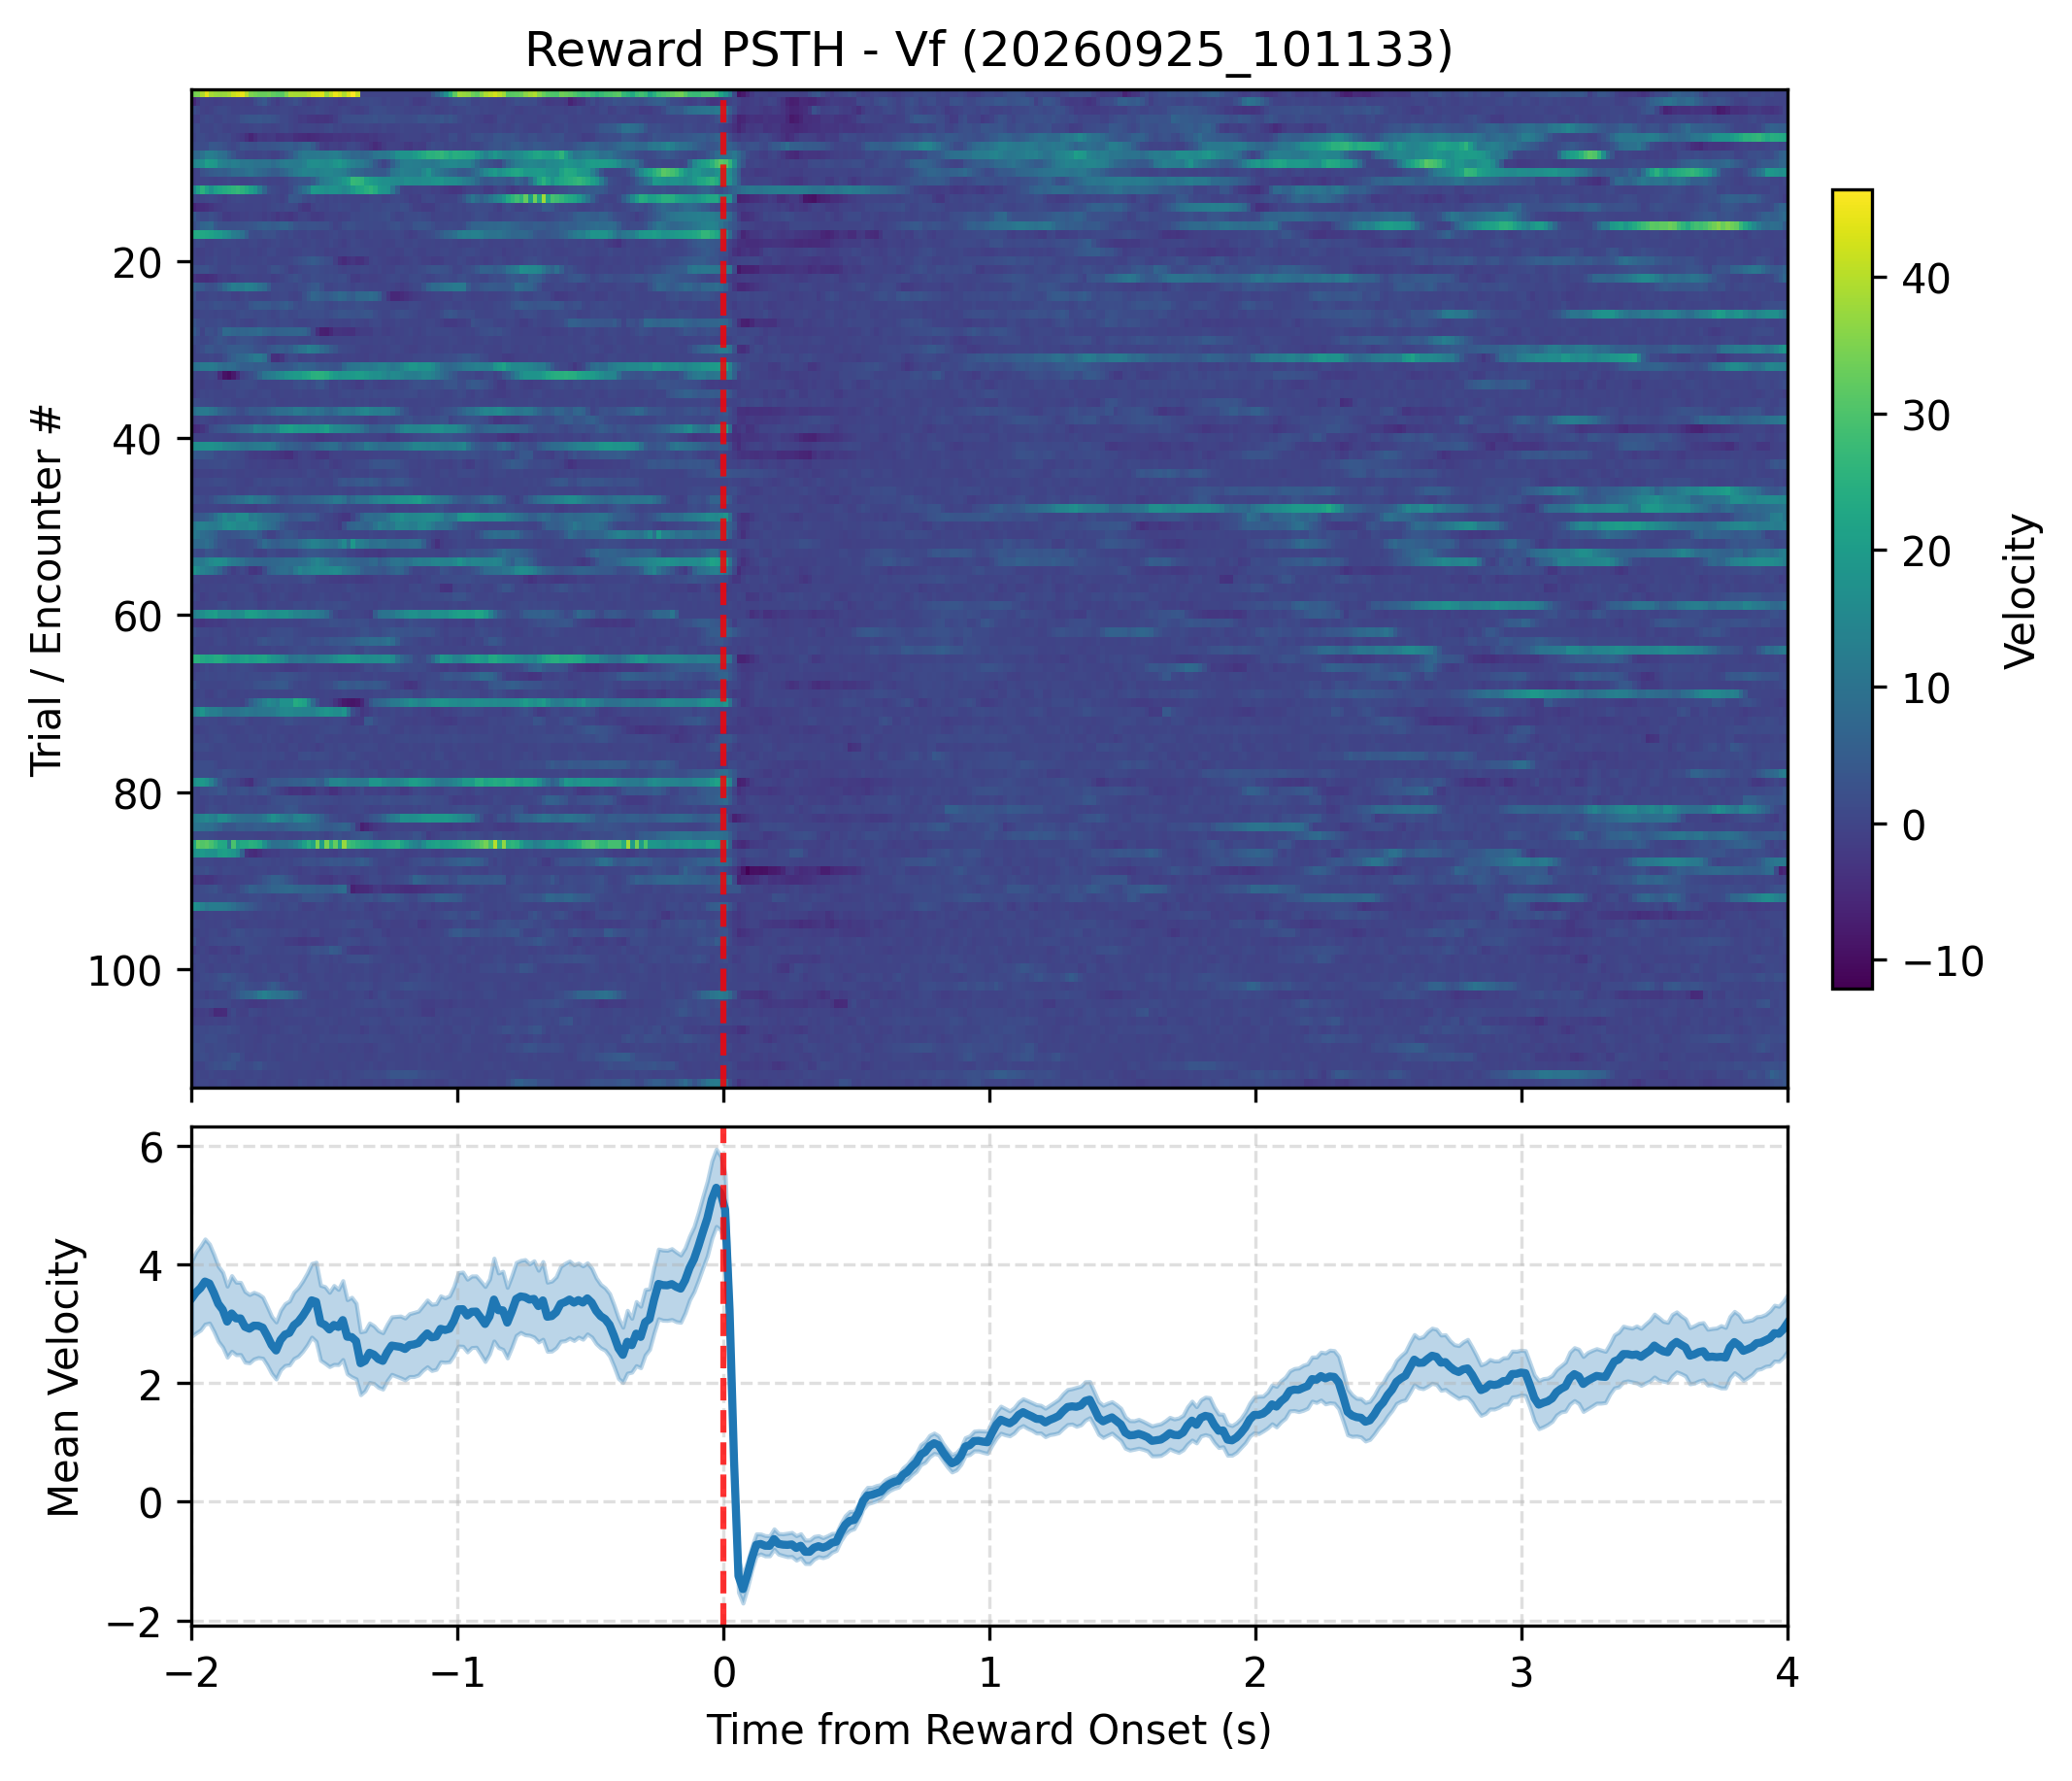

In [9]:
# Extract reward-centered windows (-2s to +4s)
psth_dict = extract_experiment_psth(
    exp, metrics=["Vf_smooth", "Vr_abs"], window_sec=(-2.0, 4.0)
)

# Plot Trial Heatmap + Average Speed Response
fig, axes = plot_single_experiment_psth(
    psth_dict, metric="Vf_smooth", title=exp["uid"]
)
plt.show()

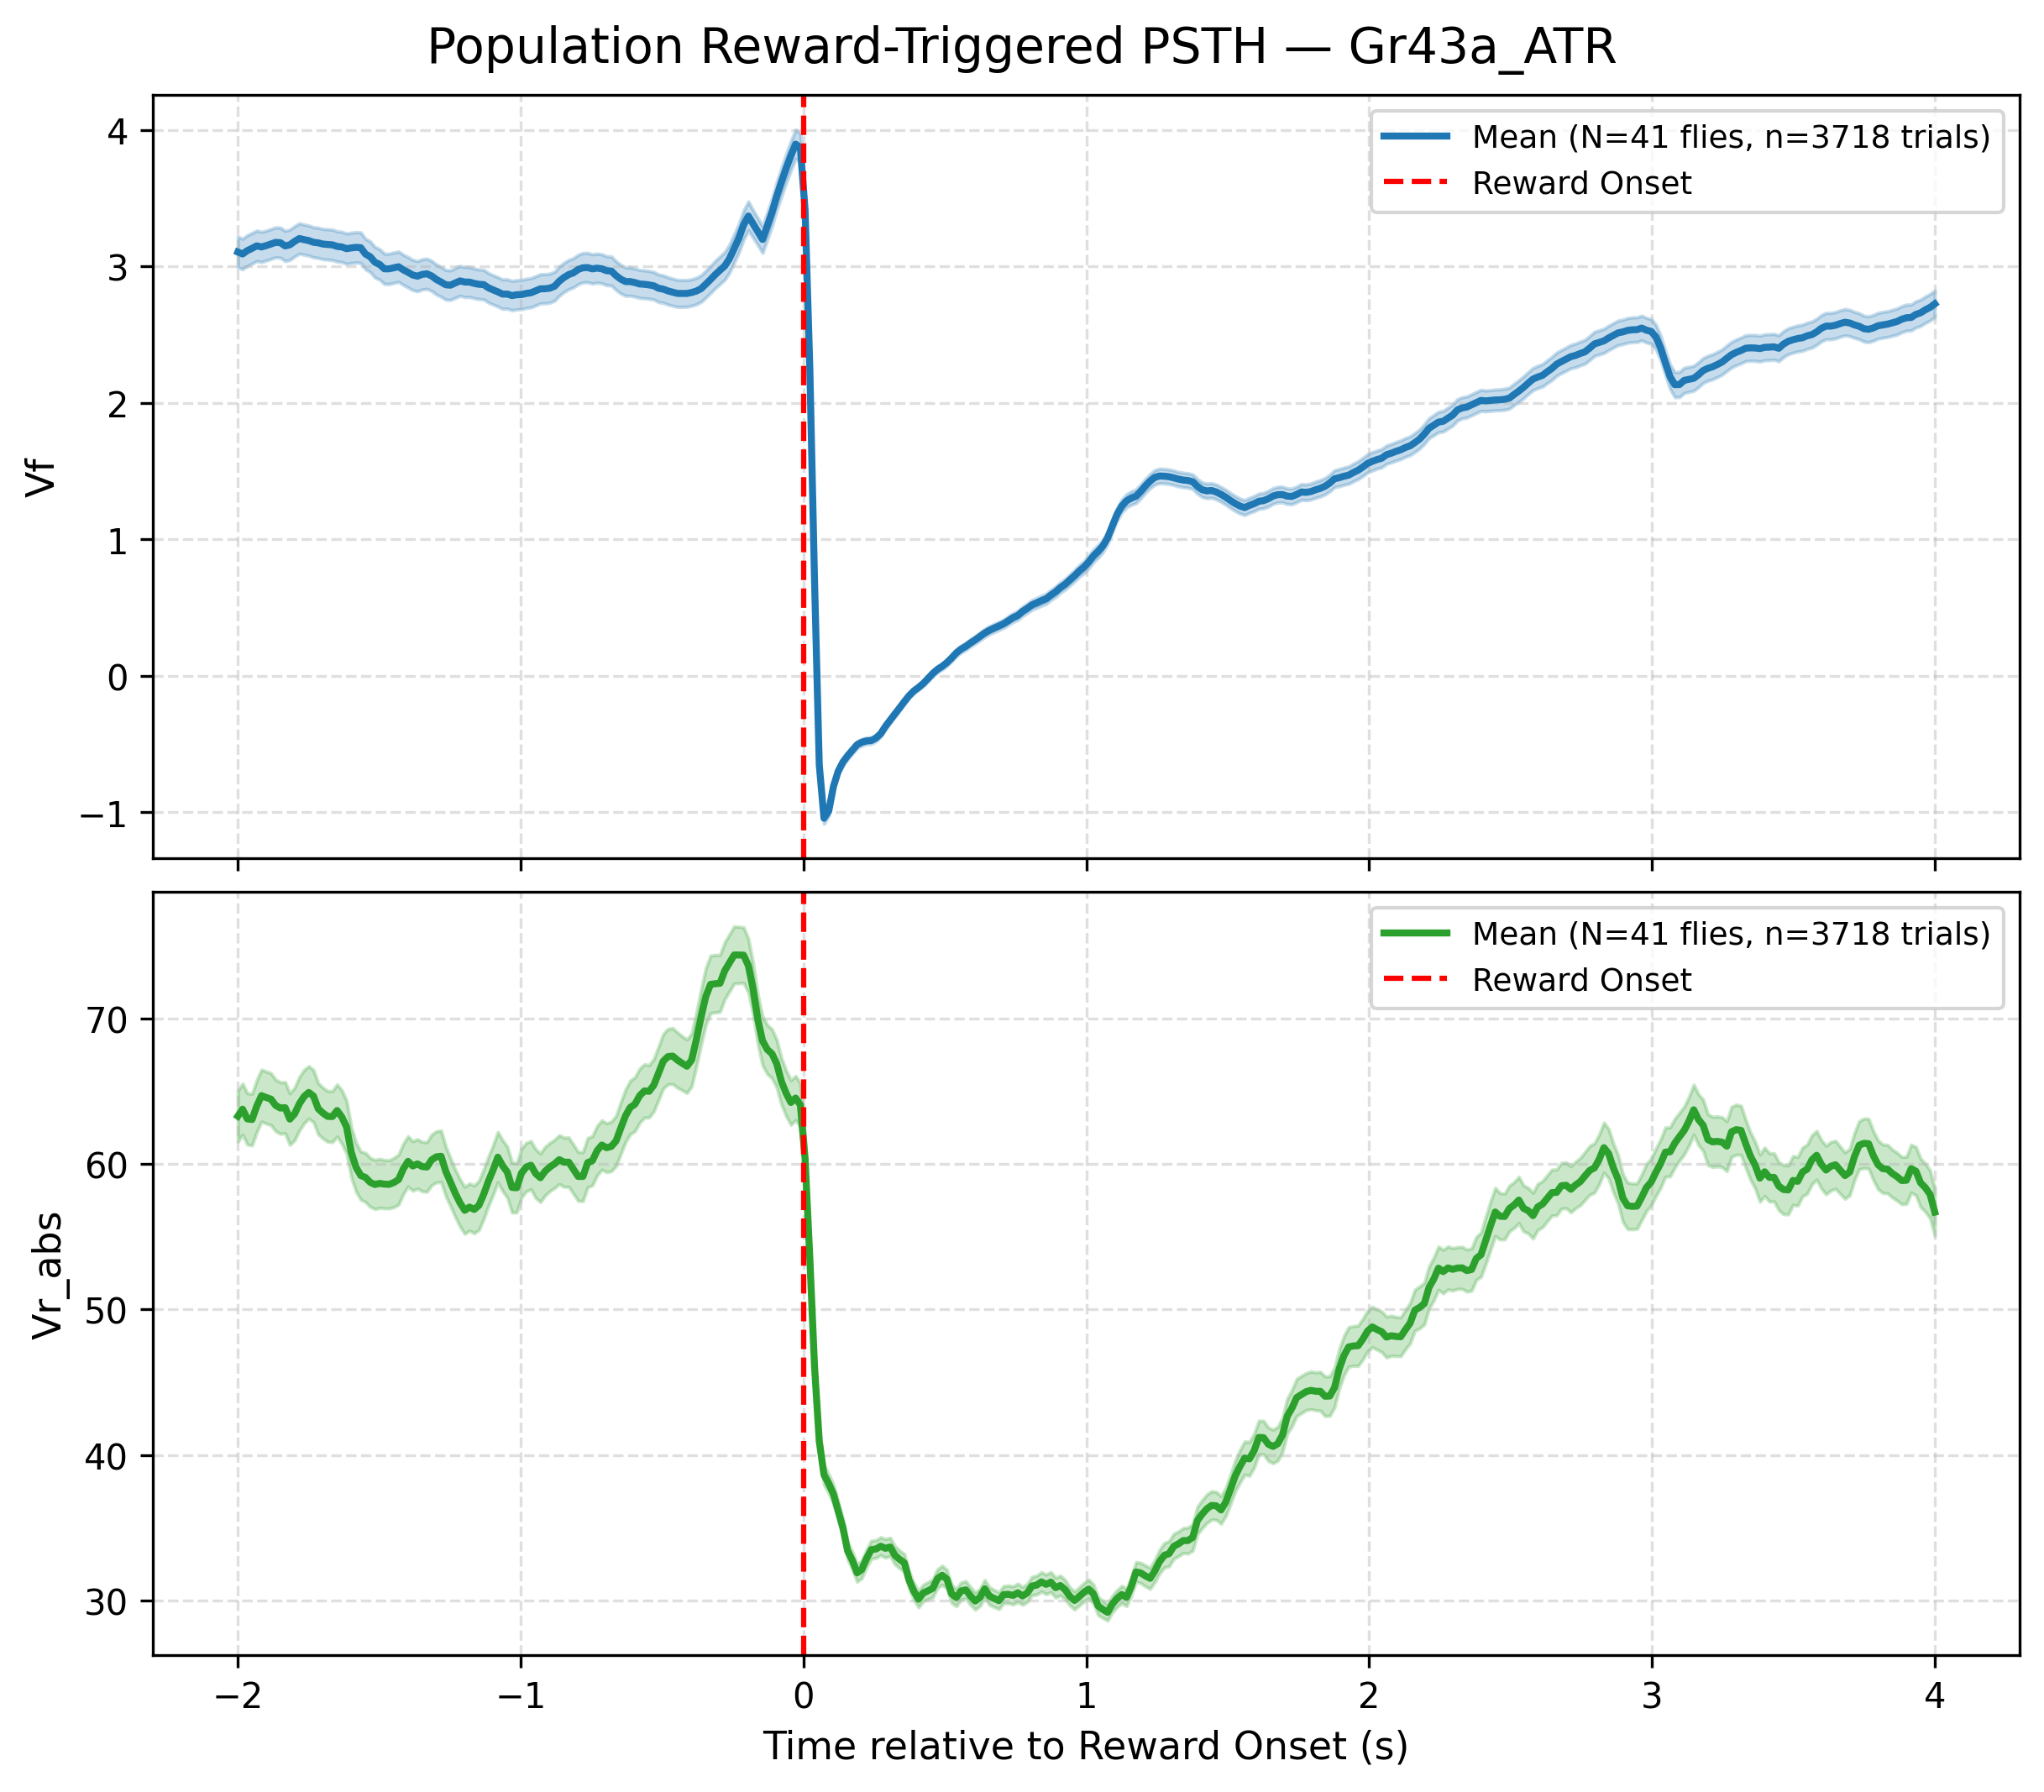

In [10]:
fig, axes = plot_condition_psth_summary(
    dataset,
    condition_name="Gr43a_ATR",
    metrics=["Vf_smooth", "Vr_abs"],
    window_sec=(-2.0, 4.0),
)
plt.show()